# v1 ensemble evaluation

Bulk-aware K=5 deep ensemble at HPO-tuned hyperparameters, evaluated on a held-out 20% test set.

This notebook is a read-only consumer of `eval_v1.json` + `predictions_val.parquet` + `predictions_test.parquet` from `scripts/06_eval_ensemble.py`.

Loads from `checkpoints/base_v1_ensemble/` by default; falls back to `checkpoints/base_v1_ensemble_rowsplit/` while the honest ensemble is still pending.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from IPython.display import Markdown, display

CANDIDATES = [
    Path('../checkpoints/base_v1_ensemble/eval_v1.json'),
    Path('checkpoints/base_v1_ensemble/eval_v1.json'),
    Path('../checkpoints/base_v1_ensemble_rowsplit/eval_v1.json'),
    Path('checkpoints/base_v1_ensemble_rowsplit/eval_v1.json'),
]
EVAL = next((p for p in CANDIDATES if p.exists()), None)
if EVAL is None:
    raise FileNotFoundError('no eval_v1.json found. Run scripts/06_eval_ensemble.py first.')
print(f'loading: {EVAL}')

with open(EVAL) as f:
    ev = json.load(f)
pred_val = pd.read_parquet(EVAL.parent / 'predictions_val.parquet')
pred_test = pd.read_parquet(EVAL.parent / 'predictions_test.parquet')

PHASES = ev['phase_names']
COND_AXES = ev['cond_axes']
COND_LABELS = ['T (C)', 'P (kbar)', 'H2O (wt%)']
K = ev['K']
n_val = ev['split_info']['n_val_rows']
n_test = ev['split_info']['n_test_rows']
print(f'K={K}  val rows={n_val}  test rows={n_test}  '
      f'classes={len(ev["val"]["per_class"])}  phases={len(PHASES)}')


loading: ../checkpoints/base_v1_ensemble/eval_v1.json
K=5  val rows=24215  test rows=30212  classes=28  phases=18


## HPO summary

Hyperparameters for the K=5 ensemble come from a single-stage Optuna TPE sweep with bulk-level 3-fold stratified CV on the 80% trainval pool. Search dims, trial counts, and the selected configuration printed below.

In [2]:
# HPO summary. best_params + best_value come from the summary JSON; trial
# counts + best trial number come from the Optuna journal (authoritative,
# since the summary JSON key names have varied across script versions).
HPO_CANDIDATES = [
    Path('../data/optuna/v1_hpo_wide_summary.json'),
    Path('data/optuna/v1_hpo_wide_summary.json'),
    Path('../data/optuna/v1_hpo_summary.json'),
    Path('data/optuna/v1_hpo_summary.json'),
]
hpo_path = next((p for p in HPO_CANDIDATES if p.exists()), None)
if hpo_path is None:
    print('No HPO summary JSON found; skipping.')
else:
    with open(hpo_path) as f:
        hpo = json.load(f)
    print(f'HPO source: {hpo_path}')

    def _fmt(x):
        if isinstance(x, bool):
            return str(x)
        if isinstance(x, float):
            if abs(x) < 0.001 or abs(x) >= 10000:
                return f'{x:.3e}'
            return f'{x:.4g}'
        return str(x)

    # Pull trial counts + top trials from the journal.
    n_complete = n_pruned = best_trial_num = None
    top3 = []
    try:
        import optuna
        from optuna.storages import JournalStorage
        from optuna.storages.journal import JournalFileBackend

        journal_path = next(
            (p for p in [hpo_path.parent / 'v1_hpo_wide.journal',
                         hpo_path.parent / 'v1_hpo.journal'] if p.exists()),
            None,
        )
        if journal_path is not None:
            study = optuna.load_study(
                study_name=hpo['study_name'],
                storage=JournalStorage(JournalFileBackend(str(journal_path))),
            )
            states = [t.state.name for t in study.trials]
            n_complete = states.count('COMPLETE')
            n_pruned = states.count('PRUNED')
            best_trial_num = study.best_trial.number
            top3 = sorted([t for t in study.trials if t.value is not None],
                          key=lambda t: t.value)[:3]
    except Exception as e:
        print(f'(journal not readable: {e})')

    rows = [
        '| field | value |',
        '|---|---|',
        f'| study | `{hpo.get("study_name", "?")}` |',
        f'| trials complete | {n_complete if n_complete is not None else "?"} |',
        f'| trials pruned | {n_pruned if n_pruned is not None else "?"} |',
        f'| best trial # | {best_trial_num if best_trial_num is not None else "?"} |',
        f'| best CV joint NLL | {hpo["best_value"]:.4f} |',
        '| **hyperparameter** | **chosen value** |',
    ]
    for k, v in hpo['best_params'].items():
        rows.append(f'| `{k}` | {_fmt(v)} |')
    display(Markdown('\n'.join(rows)))

    if top3:
        print('top-3 trials by CV joint NLL:')
        for t in top3:
            p = t.params
            print(f'  #{t.number:2d}  val={t.value:+.3f}  d_model={p.get("d_model")}'
                  f'  N={p.get("N")}  heads={p.get("heads")}  K_gmm={p.get("K_gmm")}'
                  f'  lr={p.get("lr"):.1e}  λ_cond={p.get("lambda_cond"):.2f}'
                  f'  dropout={p.get("dropout"):.3f}')


HPO source: ../data/optuna/v1_hpo_wide_summary.json


/opt/miniconda3/envs/alignn_fix/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


| field | value |
|---|---|
| study | `v1_hpo_wide` |
| trials complete | 13 |
| trials pruned | 17 |
| best trial # | 27 |
| best CV joint NLL | -53.5141 |
| **hyperparameter** | **chosen value** |
| `d_model` | 384 |
| `N` | 3 |
| `heads` | 16 |
| `dropout` | 0.1233 |
| `lr` | 2.830e-04 |
| `weight_decay` | 1.085e-05 |
| `batch_size` | 256 |
| `lambda_cond` | 1.257 |
| `K_gmm` | 3 |
| `eps_smooth` | 1.019e-04 |

top-3 trials by CV joint NLL:
  #27  val=-53.514  d_model=384  N=3  heads=16  K_gmm=3  lr=2.8e-04  λ_cond=1.26  dropout=0.123
  #21  val=-53.409  d_model=512  N=4  heads=16  K_gmm=3  lr=1.3e-04  λ_cond=3.17  dropout=0.143
  #17  val=-52.989  d_model=512  N=4  heads=16  K_gmm=2  lr=2.2e-04  λ_cond=3.21  dropout=0.122


## headline metrics

val / test side by side. NLL is mean per-sample.

In [3]:
def fmt(v, p=3):
    return f'{v:.{p}f}'

v, t = ev['val'], ev['test']
mae_v, mae_t = v['cond_mae_raw'], t['cond_mae_raw']
cov1_v, cov1_t = v['coverage_1sigma'], t['coverage_1sigma']
cov2_v, cov2_t = v['coverage_2sigma'], t['coverage_2sigma']

rows = [
    '| metric | val | test |',
    '|---|---|---|',
    f'| n samples | {v["n_samples"]:,} | {t["n_samples"]:,} |',
    f'| joint NLL (0.5/0.5) | {fmt(v["joint_nll_simple"])} | {fmt(t["joint_nll_simple"])} |',
    f'| NLL_dir (Dirichlet) | {fmt(v["nll_dir"])} | {fmt(t["nll_dir"])} |',
    f'| NLL_gmm (mean over 3 axes) | {fmt(v["nll_gmm"])} | {fmt(t["nll_gmm"])} |',
    f'| T MAE (C) | {fmt(mae_v[0], 2)} | {fmt(mae_t[0], 2)} |',
    f'| P MAE (kbar) | {fmt(mae_v[1], 2)} | {fmt(mae_t[1], 2)} |',
    f'| H2O MAE (wt%) | {fmt(mae_v[2], 3)} | {fmt(mae_t[2], 3)} |',
    f'| 1σ coverage T (nominal 0.683) | {fmt(cov1_v[0], 3)} | {fmt(cov1_t[0], 3)} |',
    f'| 1σ coverage P | {fmt(cov1_v[1], 3)} | {fmt(cov1_t[1], 3)} |',
    f'| 1σ coverage H2O | {fmt(cov1_v[2], 3)} | {fmt(cov1_t[2], 3)} |',
    f'| 2σ coverage T (nominal 0.954) | {fmt(cov2_v[0], 3)} | {fmt(cov2_t[0], 3)} |',
    f'| 2σ coverage P | {fmt(cov2_v[1], 3)} | {fmt(cov2_t[1], 3)} |',
    f'| 2σ coverage H2O | {fmt(cov2_v[2], 3)} | {fmt(cov2_t[2], 3)} |',
]
display(Markdown('\n'.join(rows)))


| metric | val | test |
|---|---|---|
| n samples | 24,215 | 30,212 |
| joint NLL (0.5/0.5) | -44.736 | -44.614 |
| NLL_dir (Dirichlet) | -87.741 | -87.495 |
| NLL_gmm (mean over 3 axes) | -1.731 | -1.733 |
| T MAE (C) | 15.58 | 15.81 |
| P MAE (kbar) | 1.65 | 1.64 |
| H2O MAE (wt%) | 0.034 | 0.034 |
| 1σ coverage T (nominal 0.683) | 0.906 | 0.904 |
| 1σ coverage P | 0.585 | 0.585 |
| 1σ coverage H2O | 0.921 | 0.920 |
| 2σ coverage T (nominal 0.954) | 0.974 | 0.972 |
| 2σ coverage P | 0.991 | 0.992 |
| 2σ coverage H2O | 1.000 | 1.000 |

## per-phase R²

val (steelblue) vs test (coral). Error bars on test = std across K members.

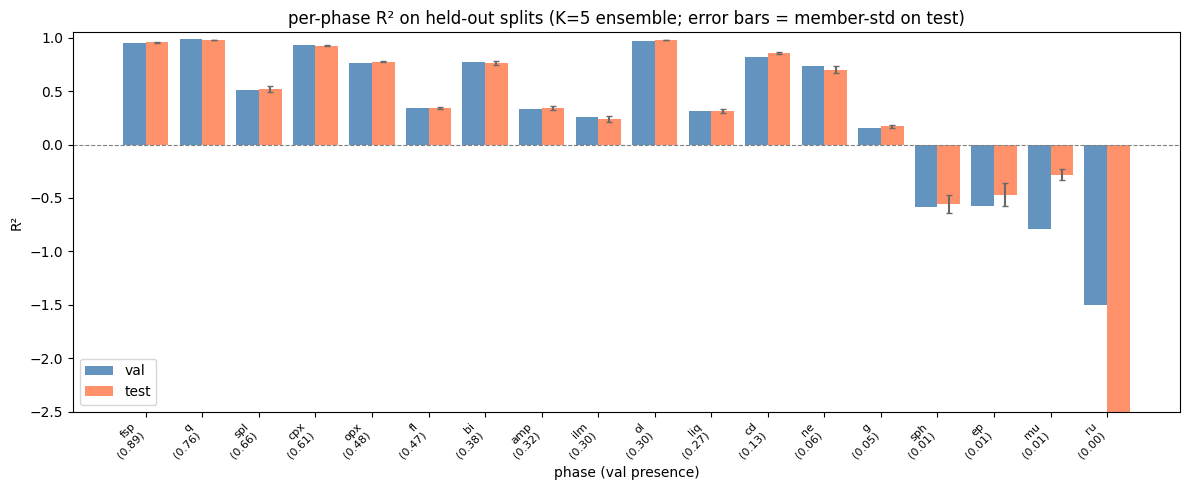

test bottom-3: ru R²=-3.91, sph R²=-0.56, ep R²=-0.47


In [4]:
r2_v = np.array(ev['val']['r2_per_phase_ensemble'])
r2_t = np.array(ev['test']['r2_per_phase_ensemble'])
r2_m = np.array(ev['test']['r2_per_phase_members'])  # [K, P]
r2_t_err = r2_m.std(axis=0)
presence_v = np.array(ev['val']['phase_presence'])
order = np.argsort(-presence_v)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(PHASES))
w = 0.4
ax.bar(x - w/2, r2_v[order], w, color='steelblue', alpha=0.85, label='val')
ax.bar(x + w/2, r2_t[order], w, color='coral', alpha=0.85, label='test',
       yerr=r2_t_err[order], ecolor='dimgray', capsize=2)
ax.axhline(0, color='gray', lw=0.8, linestyle='--')
ax.set_xticks(x)
ax.set_xticklabels([f"{PHASES[i]}\n({presence_v[i]:.2f})" for i in order],
                    rotation=45, ha='right', fontsize=8)
ax.set_ylabel('R²')
ax.set_xlabel('phase (val presence)')
ax.set_title(f'per-phase R² on held-out splits (K={K} ensemble; error bars = member-std on test)')
ax.set_ylim(-2.5, 1.05)
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

worst = sorted(zip(PHASES, r2_t.tolist()), key=lambda x: x[1])[:3]
print('test bottom-3:', ', '.join(f'{n} R²={r:.2f}' for n, r in worst))


## parity plots — conditions on test set

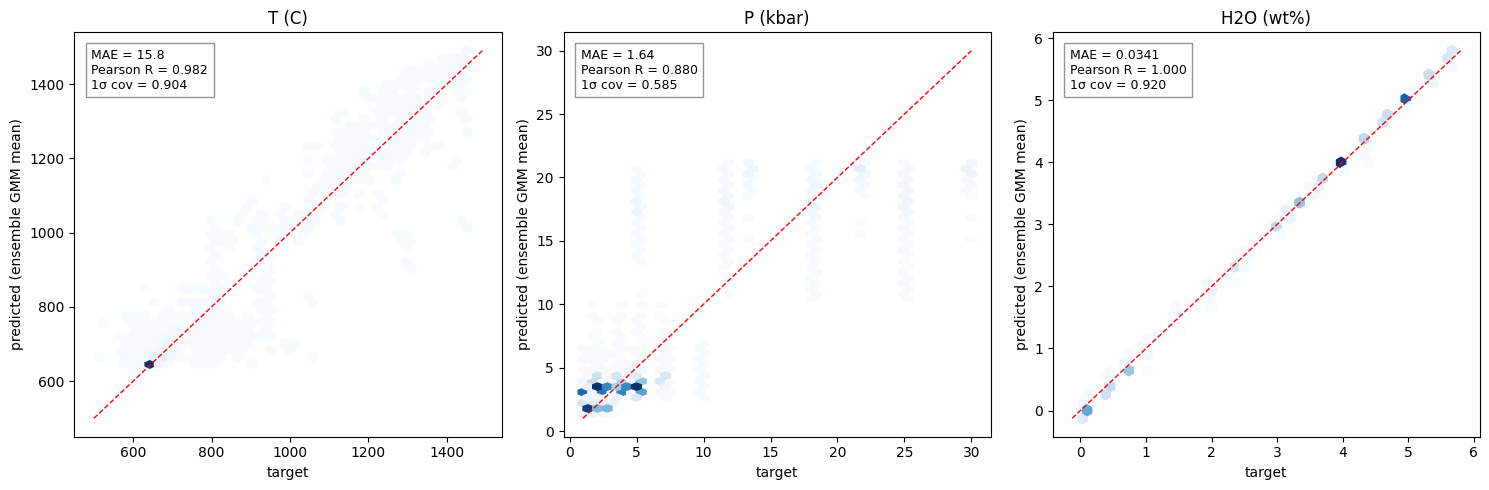

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, (ax_name, label, ax) in enumerate(zip(['T', 'P', 'H2O'], COND_LABELS, axes)):
    x = pred_test[f'target_{ax_name}'].values
    y = pred_test[f'pred_{ax_name}'].values
    hb = ax.hexbin(x, y, gridsize=40, cmap='Blues', mincnt=1)
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([lo, hi], [lo, hi], color='r', linestyle='--', lw=1.0)
    mae = np.abs(x - y).mean()
    pr = pearsonr(x, y).statistic
    sig = pred_test[f'sigma_{ax_name}'].values
    cov1 = float(((np.abs(x - y) <= sig).mean()))
    ax.set_title(f'{label}')
    ax.set_xlabel('target')
    ax.set_ylabel('predicted (ensemble GMM mean)')
    ax.text(0.04, 0.96,
            f'MAE = {mae:.3g}\nPearson R = {pr:.3f}\n1σ cov = {cov1:.3f}',
            transform=ax.transAxes, ha='left', va='top',
            fontsize=9, bbox=dict(facecolor='white', alpha=0.85, edgecolor='gray'))
plt.tight_layout()
plt.show()


## calibration reliability plot

empirical 1σ coverage by predicted-σ bucket (10 equal-frequency bins). Well calibrated = horizontal at 0.683. Above = underconfident; below = overconfident.

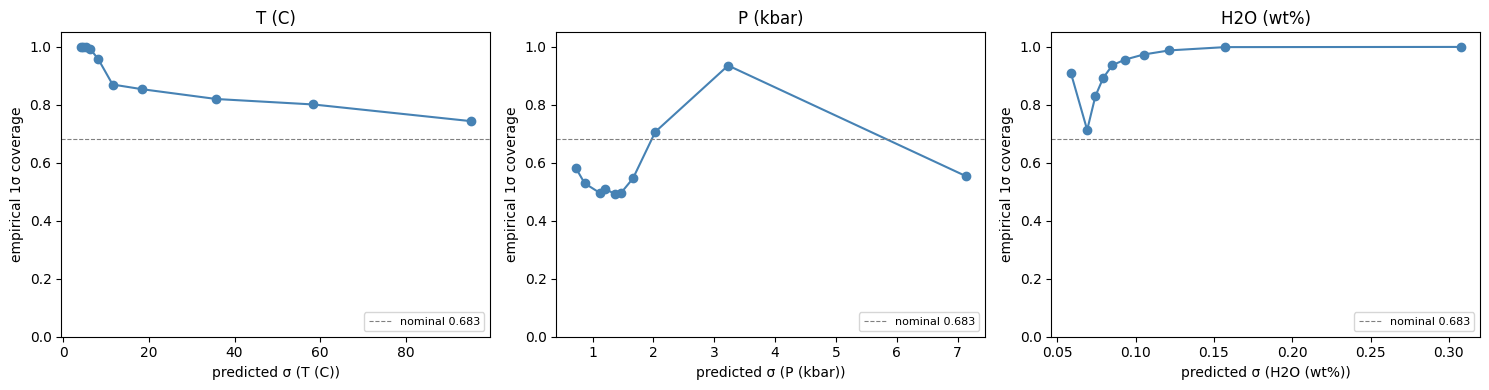

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax_name, label, ax in zip(['T', 'P', 'H2O'], COND_LABELS, axes):
    err = (pred_test[f'pred_{ax_name}'] - pred_test[f'target_{ax_name}']).abs().values
    sig = pred_test[f'sigma_{ax_name}'].values
    nbins = 10
    edges = np.quantile(sig, np.linspace(0, 1, nbins + 1))
    centers, cov = [], []
    for j in range(nbins):
        lo, hi = edges[j], edges[j + 1]
        if j == nbins - 1:
            mask = (sig >= lo) & (sig <= hi)
        else:
            mask = (sig >= lo) & (sig < hi)
        if mask.sum() == 0:
            continue
        cov.append(float((err[mask] <= sig[mask]).mean()))
        centers.append(float(sig[mask].mean()))
    ax.plot(centers, cov, marker='o', color='steelblue', lw=1.5)
    ax.axhline(0.683, color='gray', linestyle='--', lw=0.8, label='nominal 0.683')
    ax.set_xlabel(f'predicted σ ({label})')
    ax.set_ylabel('empirical 1σ coverage')
    ax.set_title(label)
    ax.set_ylim(0, 1.05)
    ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()


## σ vs |error| scatter

positive Pearson correlation = well-behaved heteroscedastic uncertainty (the model is more uncertain on harder examples).

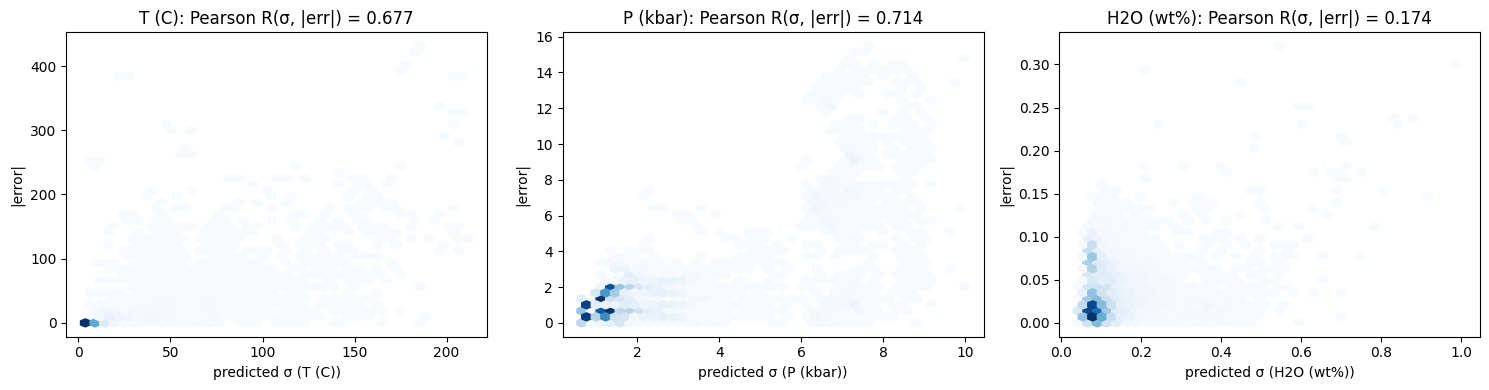

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax_name, label, ax in zip(['T', 'P', 'H2O'], COND_LABELS, axes):
    err = (pred_test[f'pred_{ax_name}'] - pred_test[f'target_{ax_name}']).abs().values
    sig = pred_test[f'sigma_{ax_name}'].values
    hb = ax.hexbin(sig, err, gridsize=40, cmap='Blues', mincnt=1)
    pr = pearsonr(sig, err).statistic
    ax.set_xlabel(f'predicted σ ({label})')
    ax.set_ylabel('|error|')
    ax.set_title(f'{label}: Pearson R(σ, |err|) = {pr:.3f}')
plt.tight_layout()
plt.show()


## per-class R² heatmap (test)

Classes (rows) × phases (cols). Cells where presence within that class < 1% are masked (uninterpretable R²).

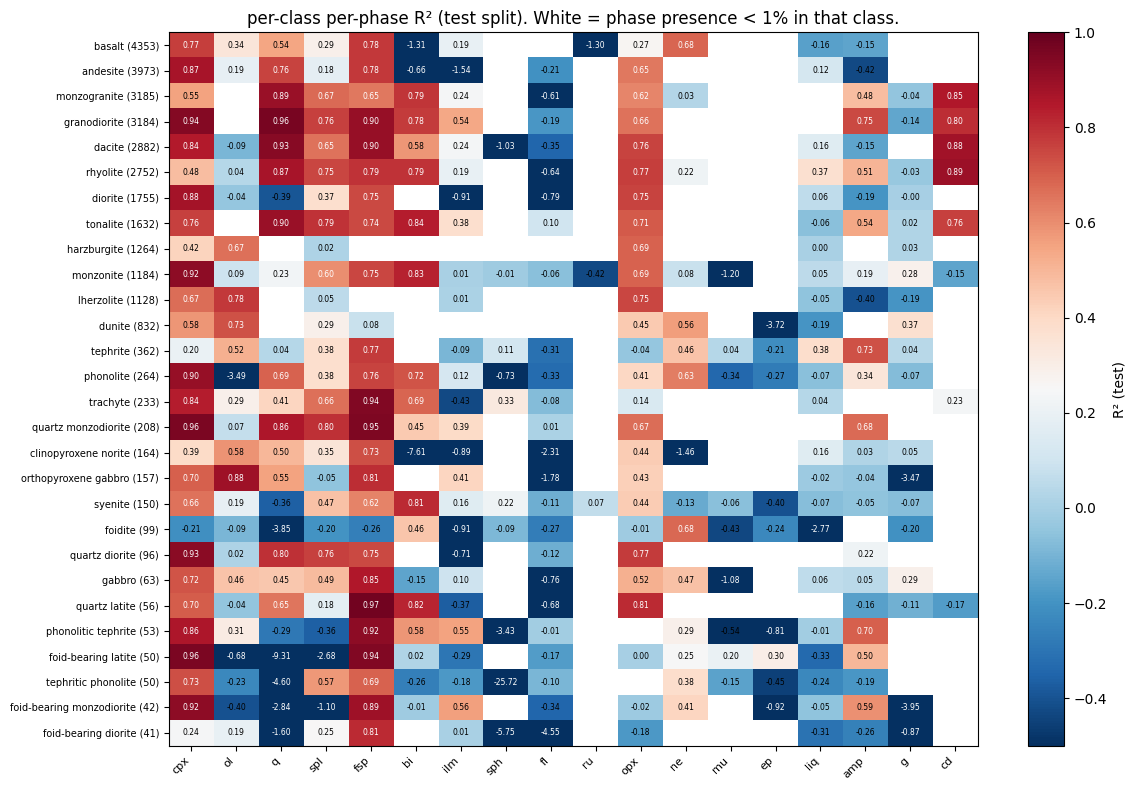

In [8]:
per_class = ev['test']['per_class']
classes_sorted = sorted(per_class.keys(), key=lambda c: -per_class[c]['n_samples'])

mat = np.full((len(classes_sorted), len(PHASES)), np.nan)
for ci, cls in enumerate(classes_sorted):
    block = per_class[cls]
    for pi, ph in enumerate(PHASES):
        if ph in block['per_phase_r2']:
            mat[ci, pi] = block['per_phase_r2'][ph]

fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(mat, aspect='auto', cmap='RdBu_r', vmin=-0.5, vmax=1.0)
plt.colorbar(im, ax=ax, label='R² (test)')
ax.set_xticks(np.arange(len(PHASES)))
ax.set_xticklabels(PHASES, rotation=45, ha='right', fontsize=8)
ax.set_yticks(np.arange(len(classes_sorted)))
ax.set_yticklabels([f'{c} ({per_class[c]["n_samples"]})' for c in classes_sorted], fontsize=7)
ax.set_title('per-class per-phase R² (test split). White = phase presence < 1% in that class.')
for ci in range(mat.shape[0]):
    for pi in range(mat.shape[1]):
        if not np.isnan(mat[ci, pi]):
            txt_color = 'white' if abs(mat[ci, pi]) > 0.6 else 'black'
            ax.text(pi, ci, f'{mat[ci, pi]:.2f}', ha='center', va='center',
                    fontsize=5.5, color=txt_color)
plt.tight_layout()
plt.show()


## per-class condition MAE (test)

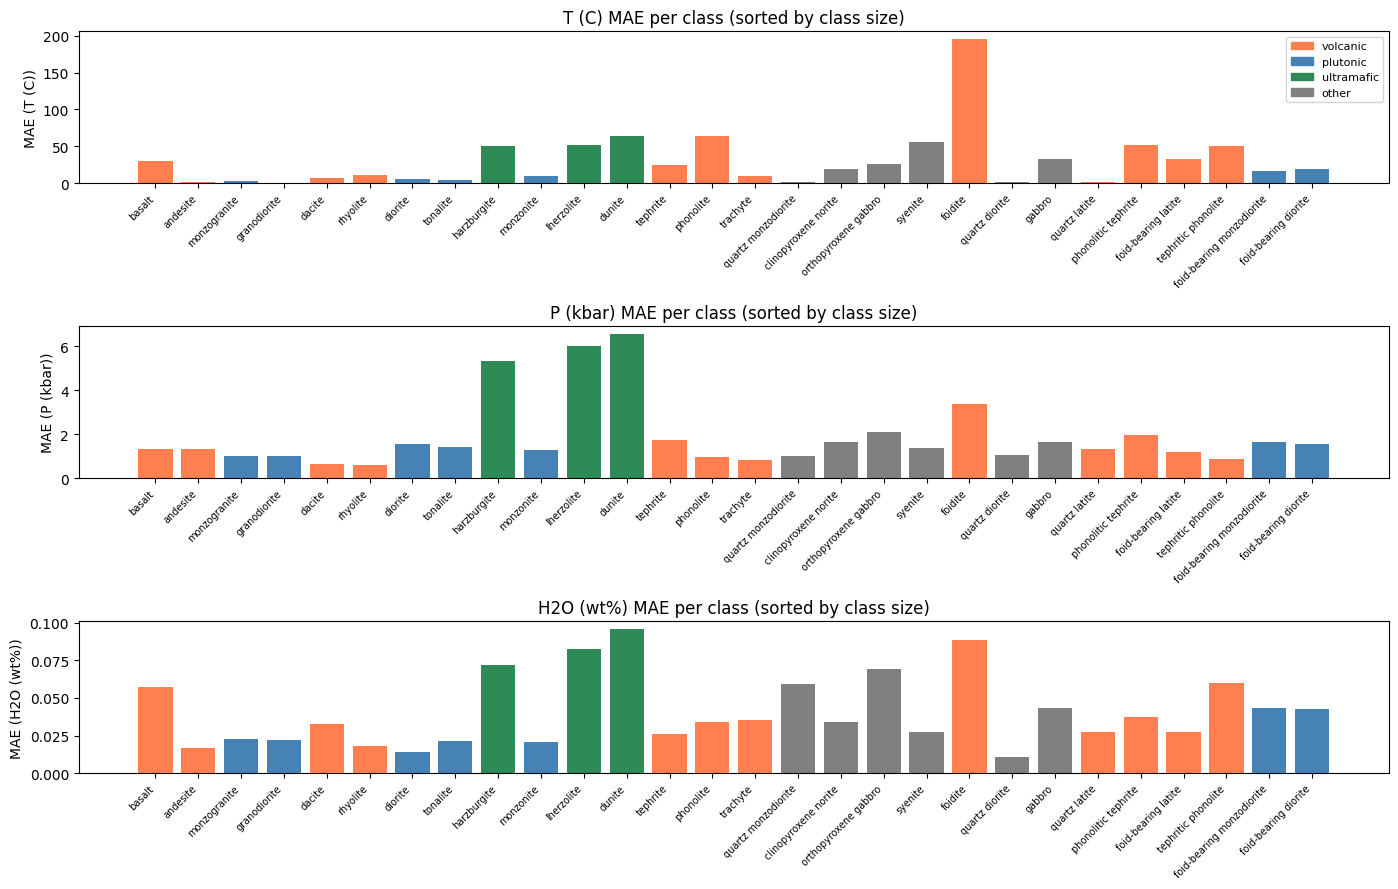

In [9]:
# rough family grouping for colour
VOLCANIC = {'basalt', 'andesite', 'dacite', 'rhyolite', 'trachyte', 'phonolite',
            'foidite', 'tephrite', 'tephritic phonolite', 'phonolitic tephrite',
            'phonolitic basanite', 'foid-bearing trachyte', 'latite', 'quartz latite',
            'foid-bearing latite', 'alkali feldspar quartz trachyte',
            'foid-bearing alkali feldspar trachyte'}
PLUTONIC = {'monzogranite', 'granodiorite', 'diorite', 'tonalite', 'monzonite',
            'monzodiorite', 'syenogranite', 'quartz monzonite', 'quartz-rich rhyolite',
            'quartz-rich granitoid', 'norite', 'foid-bearing monzonite',
            'foid-bearing monzodiorite', 'foid-bearing diorite', 'foid monzodiorite',
            'foid monzosyenite', 'foid-bearing syenite'}
ULTRAMAFIC = {'lherzolite', 'harzburgite', 'dunite', 'wherlite',
              'olivine websterite', 'plagioclase-bearing websterite',
              'clinopyroxenite', 'orthopyroxenite', 'olivine orthopyroxenite'}

def family(cls):
    if cls in VOLCANIC: return 'volcanic'
    if cls in PLUTONIC: return 'plutonic'
    if cls in ULTRAMAFIC: return 'ultramafic'
    return 'other'

palette = {'volcanic': 'coral', 'plutonic': 'steelblue',
           'ultramafic': 'seagreen', 'other': 'gray'}

fig, axes = plt.subplots(3, 1, figsize=(14, 9))
for i, (ax_name, label, ax) in enumerate(zip(['T', 'P', 'H2O'], COND_LABELS, axes)):
    items = [(c, per_class[c]['cond_mae_raw'][i]) for c in classes_sorted]
    classes_x = [c for c, _ in items]
    vals = [v for _, v in items]
    colors = [palette[family(c)] for c in classes_x]
    ax.bar(range(len(classes_x)), vals, color=colors)
    ax.set_xticks(range(len(classes_x)))
    ax.set_xticklabels(classes_x, rotation=45, ha='right', fontsize=7)
    ax.set_ylabel(f'MAE ({label})')
    ax.set_title(f'{label} MAE per class (sorted by class size)')

from matplotlib.patches import Patch
legend_h = [Patch(color=palette[f], label=f) for f in ['volcanic', 'plutonic', 'ultramafic', 'other']]
axes[0].legend(handles=legend_h, loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()


## leakage gap

row-leaked ensemble re-evaluated on the SAME bulk-level splits. Numbers in this section only render if `--compare-dir` was passed to `06_eval_ensemble.py`.

| metric | bulk-split (honest) | rowleak (re-eval) | delta |
|---|---|---|---|
| TEST joint NLL | -44.614 | -46.979 | -2.365 |
| val joint NLL | -44.736 | -47.016 | -2.279 |
| TEST T MAE (C) | 15.81 | 6.42 | -9.38 |
| TEST P MAE (kbar) | 1.64 | 1.62 | -0.03 |
| TEST H2O MAE (wt%) | 0.034 | 0.016 | -0.018 |

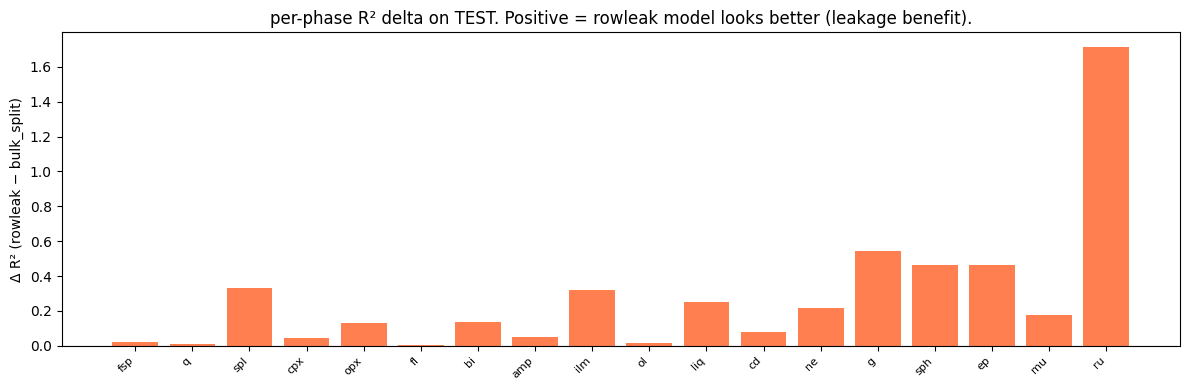

In [10]:
if 'leakage_gap' not in ev:
    print('No leakage_gap block in eval_v1.json. Skip this section.')
    print('  Re-run scripts/06_eval_ensemble.py with --compare-dir checkpoints/base_v1_ensemble_rowsplit')
else:
    lg = ev['leakage_gap']
    rows = [
        '| metric | bulk-split (honest) | rowleak (re-eval) | delta |',
        '|---|---|---|---|',
    ]
    for k, label, p in [
        ('test', 'TEST joint NLL', 3),
        ('val', 'val joint NLL', 3),
    ]:
        b = lg[k]['joint_nll_simple_bulk_split']
        r = lg[k]['joint_nll_simple_compare_reeval']
        rows.append(f'| {label} | {b:.{p}f} | {r:.{p}f} | {r-b:+.{p}f} |')
    for k, ax, label, p in [
        ('test', 0, 'TEST T MAE (C)', 2),
        ('test', 1, 'TEST P MAE (kbar)', 2),
        ('test', 2, 'TEST H2O MAE (wt%)', 3),
    ]:
        b = lg[k]['cond_mae_raw_bulk_split'][ax]
        r = lg[k]['cond_mae_raw_compare_reeval'][ax]
        rows.append(f'| {label} | {b:.{p}f} | {r:.{p}f} | {r-b:+.{p}f} |')
    display(Markdown('\n'.join(rows)))

    # delta R² bar chart (test)
    r2_b = np.array(lg['test']['r2_per_phase_bulk_split'])
    r2_r = np.array(lg['test']['r2_per_phase_compare_reeval'])
    delta = r2_r - r2_b
    pres = np.array(ev['test']['phase_presence'])
    order = np.argsort(-pres)
    fig, ax = plt.subplots(figsize=(12, 4))
    colors = ['coral' if d > 0 else 'steelblue' for d in delta[order]]
    ax.bar(range(len(PHASES)), delta[order], color=colors)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xticks(range(len(PHASES)))
    ax.set_xticklabels([PHASES[i] for i in order], rotation=45, ha='right', fontsize=8)
    ax.set_ylabel('Δ R² (rowleak − bulk_split)')
    ax.set_title('per-phase R² delta on TEST. Positive = rowleak model looks better (leakage benefit).')
    plt.tight_layout()
    plt.show()


## modal mass balance: ground truth vs prediction

For a sample of test rocks, paired stacked bars show every phase's wt fraction. Left bar (each pair) = MAGEMin FC ground truth. Right bar = ensemble Dirichlet mean prediction. Total height ≈ 1.0 for both.

Each x-tick is one test path-row, labeled with `sample_id` + `qap_name`. Iterate on count / sort / palette as needed.

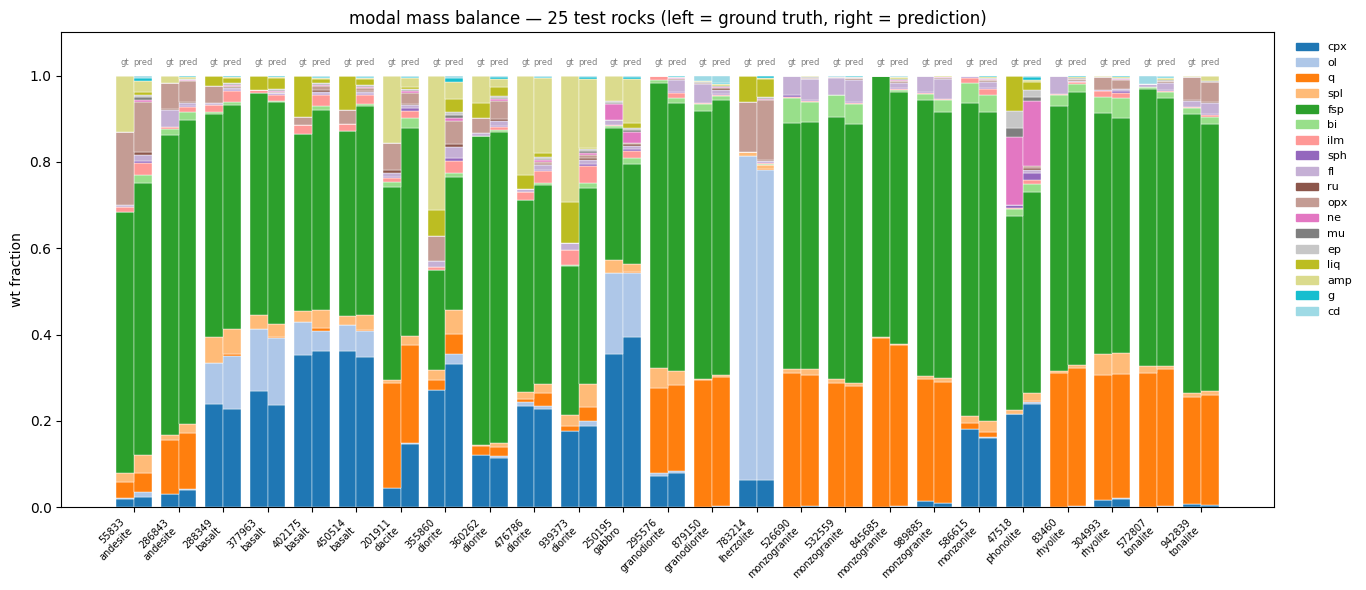


L1 disagreement across the 25 rocks: mean=0.173  median=0.112  max=0.613  (2.0 = total mismatch; 0.0 = exact)


In [12]:
import matplotlib.patches as mpatches

N_ROCKS = 25
SAMPLE_SEED = 42
SORT_BY = 'qap_name'  # 'random' | 'qap_name' | 'sample_id'

rng = np.random.default_rng(SAMPLE_SEED)
idx = rng.choice(len(pred_test), size=min(N_ROCKS, len(pred_test)), replace=False)
sub = pred_test.iloc[idx].copy()
if SORT_BY == 'qap_name':
    sub = sub.sort_values(['qap_name', 'sample_id']).reset_index(drop=True)
elif SORT_BY == 'sample_id':
    sub = sub.sort_values('sample_id').reset_index(drop=True)
else:
    sub = sub.reset_index(drop=True)

N = len(sub)
phase_colors = plt.cm.tab20(np.linspace(0, 1, len(PHASES)))
bar_w = 0.4
x = np.arange(N)

fig, ax = plt.subplots(figsize=(max(12, 0.55 * N), 6))
bottom_gt = np.zeros(N)
bottom_pred = np.zeros(N)
for i, ph in enumerate(PHASES):
    gt = sub[f'target_{ph}'].values
    pr = sub[f'pred_{ph}'].values
    ax.bar(x - bar_w / 2, gt, bar_w, bottom=bottom_gt,
           color=phase_colors[i], edgecolor='white', linewidth=0.3)
    ax.bar(x + bar_w / 2, pr, bar_w, bottom=bottom_pred,
           color=phase_colors[i], edgecolor='white', linewidth=0.3)
    bottom_gt += gt
    bottom_pred += pr

# Annotate each pair: 'gt' on left, 'pred' on right, just above the bar
for j in range(N):
    ax.text(j - bar_w / 2, 1.02, 'gt', ha='center', va='bottom', fontsize=6, color='gray')
    ax.text(j + bar_w / 2, 1.02, 'pred', ha='center', va='bottom', fontsize=6, color='gray')

labels = [f"{sid}\n{cls}" for sid, cls in zip(sub['sample_id'], sub['qap_name'])]
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=7)
ax.set_ylabel('wt fraction')
ax.set_title(f'modal mass balance — {N} test rocks (left = ground truth, right = prediction)')
ax.set_ylim(0, 1.10)

handles = [mpatches.Patch(color=phase_colors[i], label=PHASES[i]) for i in range(len(PHASES))]
ax.legend(handles=handles, bbox_to_anchor=(1.01, 1), loc='upper left',
          fontsize=8, ncol=1, frameon=False)
plt.tight_layout()
plt.show()

# Per-rock disagreement (L1 distance between GT and predicted modal vectors)
gt_mat = sub[[f'target_{p}' for p in PHASES]].to_numpy()
pred_mat = sub[[f'pred_{p}' for p in PHASES]].to_numpy()
l1 = np.abs(gt_mat - pred_mat).sum(axis=1)
print(f'\nL1 disagreement across the {N} rocks: mean={l1.mean():.3f}  '
      f'median={np.median(l1):.3f}  max={l1.max():.3f}  '
      f'(2.0 = total mismatch; 0.0 = exact)')


## simulated user inference

A geologist has a whole-rock ICP/XRF analysis — one row of `complete.csv` — and wants the predicted mineral assemblage and formation conditions. This section loads the K=5 ensemble and runs a real forward pass on a held-out **test** rock (never seen in training), printing the report the model would hand back.

The rock is chosen by `DEMO_SAMPLE_ID` below; set it to any test-set `sample_id`, or leave `None` for a random draw.

**Caveat:** the H2O axis is currently target-leaked — input oxide `h2o_tot` equals the CondHead H2O target `h2o_path_wt`, so the H2O "prediction" is a copy of the input. It is flagged in the output. The fix (drop `h2o_tot` from inputs, retrain) is a pending Stage-3 item; T and P are genuine inverse-inference predictions.

In [ ]:
import sys, os
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
sys.path.insert(0, str((EVAL.parent.parent.parent / 'src').resolve()))
import torch
from cnmineral.models.model import BaseModelV1
from cnmineral.models.dataset import TrainFCv1Dataset, V1_OXIDE_COLS

REPO = EVAL.parent.parent.parent
ENS_DIR = EVAL.parent
DEMO_SAMPLE_ID = None   # any test-set sample_id, or None for a random draw

# --- one-time setup: K=5 ensemble + test-split dataset + raw oxide lookup ---
if 'demo_members' not in globals():
    _splits = json.load(open(REPO / 'data/splits_v1.json'))
    _test_ids = set(_splits['test_sample_ids'])
    demo_ds = TrainFCv1Dataset(REPO / 'data/train_fc_v1.parquet',
                               sample_id_filter=list(_test_ids))
    # raw oxide wt% per row, so the demo can show the geologist-facing input
    demo_oxides = pd.read_parquet(
        REPO / 'data/train_fc_v1.parquet',
        columns=['sample_id', 'path_idx'] + V1_OXIDE_COLS,
    )
    demo_oxides = demo_oxides[demo_oxides['sample_id'].isin(_test_ids)].reset_index(drop=True)
    demo_members = []
    for _d in sorted(ENS_DIR.glob('seed_*')):
        _ck = torch.load(_d / 'best.pt', map_location='cpu', weights_only=False)
        _mc = _ck['config']['model']
        _m = BaseModelV1(n_minerals=_ck['n_minerals'], K_gmm=_ck['K_gmm'],
                         d_model=_mc['d_model'], N=_mc['N'], heads=_mc['heads'],
                         dropout=_mc['dropout'], elem_prop=_mc['elem_prop'],
                         mode_hidden=_mc.get('mode_hidden'),
                         cond_hidden=_mc.get('cond_hidden'),
                         alpha_floor=_mc.get('alpha_floor', 1e-3))
        _m.load_state_dict(_ck['model_state_dict'])
        _m.eval()
        demo_members.append(_m)
    demo_cond_mean = np.asarray(_ck['cond_mean'])
    demo_cond_std = np.asarray(_ck['cond_std'])
    print(f'loaded K={len(demo_members)} ensemble members; test pool = {len(demo_ds)} rows')


def predict_rock(sample_id=None):
    """Run the K=5 ensemble on one held-out test rock; return a report dict."""
    sids = demo_ds.sample_ids
    if sample_id is None:
        sample_id = int(np.random.default_rng().choice(np.unique(sids)))
    rows = np.where(sids == sample_id)[0]
    if len(rows) == 0:
        raise ValueError(f'sample_id {sample_id} not in the test split')
    item = demo_ds[int(rows[0])]   # first FC path of this bulk

    src = item['src'].unsqueeze(0)
    frac = item['frac'].unsqueeze(0)
    alphas, cmu_z, cvar_z = [], [], []
    with torch.no_grad():
        for m in demo_members:
            out = m(src, frac)
            alphas.append(out['alpha'].numpy()[0])
            mu = out['cond_means'].numpy()[0]                # [3, K_gmm]
            ls = out['cond_log_sigmas'].numpy()[0]
            ml = out['cond_mix_logits'].numpy()[0]
            w = np.exp(ml - ml.max(axis=-1, keepdims=True))
            w = w / w.sum(axis=-1, keepdims=True)
            sig = np.exp(ls)
            axis_mu = (w * mu).sum(-1)
            axis_var = (w * (mu**2 + sig**2)).sum(-1) - axis_mu**2
            cmu_z.append(axis_mu)
            cvar_z.append(axis_var)
    A = np.stack(alphas, 0)                                  # [K, n_phases]
    ens_modal = A.mean(0) / A.mean(0).sum()
    member_modal = A / A.sum(axis=1, keepdims=True)
    epi_modal = member_modal.std(0)

    cmu_z = np.stack(cmu_z, 0); cvar_z = np.stack(cvar_z, 0)  # [K, 3]
    ens_mu_z = cmu_z.mean(0)
    ens_sig_z = np.sqrt(cvar_z.mean(0) + cmu_z.var(0))        # aleatoric + epistemic
    cond_mu = ens_mu_z * demo_cond_std + demo_cond_mean
    cond_sig = ens_sig_z * demo_cond_std

    ox_row = demo_oxides[(demo_oxides['sample_id'] == sample_id)
                         & (demo_oxides['path_idx'] == 0)]
    oxides = {c: float(ox_row[c].iloc[0]) for c in V1_OXIDE_COLS}

    return {
        'sample_id': sample_id, 'qap_name': item['qap_name'], 'oxides': oxides,
        'pred_modal': ens_modal, 'epi_modal': epi_modal,
        'cond_mu': cond_mu, 'cond_sig': cond_sig,
        'gt_modal': item['y_modal'].numpy(),
        'gt_cond': item['y_cond_z'].numpy() * demo_cond_std + demo_cond_mean,
    }


def print_report(r):
    print('=' * 60)
    print('CrabNet-Mineral v1  --  simulated user inference')
    print('=' * 60)
    print(f'specimen: complete.csv sample_id={r["sample_id"]}  qap_name={r["qap_name"]}')
    print('input (11 oxide wt%):')
    print('  ' + '  '.join(f'{k}={v:g}' for k, v in r['oxides'].items()))
    print()
    print(f'{"  phase  pred%  +/- epi":<30}{"truth%":<10}')
    order = np.argsort(-r['pred_modal'])
    for i in order:
        if r['pred_modal'][i] < 0.005 and r['gt_modal'][i] < 0.005:
            continue
        pred = (f"  {demo_ds.phase_names[i]:5s} {100*r['pred_modal'][i]:5.1f}"
                f"  +/- {100*r['epi_modal'][i]:.1f}")
        print(f"{pred:<30}{100*r['gt_modal'][i]:6.1f}")
    l1 = np.abs(r['pred_modal'] - r['gt_modal']).sum()
    print(f'  modal L1 error: {l1:.3f}  (0 = exact, 2 = max)')
    print()
    print(f'{"  predicted conditions":<36}{"truth":<12}')
    for name, unit, j in [('T', 'C', 0), ('P', 'kbar', 1), ('H2O', 'wt%', 2)]:
        tag = '  <-- LEAKED (= h2o_tot input)' if name == 'H2O' else ''
        line = f"  {name:4s}= {r['cond_mu'][j]:7.2f} +/- {r['cond_sig'][j]:6.2f} {unit}"
        print(f"{line:<36}{r['gt_cond'][j]:7.2f} {unit}{tag}")
    print('=' * 60)


_report = predict_rock(DEMO_SAMPLE_ID)
print_report(_report)
